In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
)

url = (
    "https://raw.githubusercontent.com/DataTalksClub/"
    "machine-learning-zoomcamp/main/cohorts/2026/data/"
    "course_lead_scoring_2026.csv"
)

df = pd.read_csv(url)

print("Пропуски:")
print(df.isna().sum())

features = df.drop(columns="converted")

categorical = features.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical = features.select_dtypes(
    include="number"
).columns.tolist()

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"].to_numpy()
y_val = df_val["converted"].to_numpy()

print("\nРазмеры выборок:")
print(len(df_train), len(df_val), len(df_test))

Пропуски:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Размеры выборок:
3000 1000 1000


In [2]:
feature_auc = {}

for column in numerical:
    scores = df_train[column]

    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)

    feature_auc[column] = auc
    print(f"{column}: {auc:.6f}")

print("\nОтвет Q1:", max(feature_auc, key=feature_auc.get))

annual_income: 0.608198
number_of_courses_viewed: 0.722989
interaction_count: 0.764920
lead_score: 0.788225

Ответ Q1: lead_score


In [4]:
def fit_predict(train_df, val_df, C=1.0):
    train_features = train_df.drop(columns="converted")
    val_features = val_df.drop(columns="converted")

    train_dicts = train_features.to_dict(orient="records")
    val_dicts = val_features.to_dict(orient="records")

    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000,
    )

    model.fit(X_train, train_df["converted"].to_numpy())
    return model.predict_proba(X_val)[:, 1]


y_prob = fit_predict(df_train, df_val)

auc = roc_auc_score(y_val, y_prob)

print("ROC AUC:", auc)
print("Ответ Q2:", round(auc, 3))

ROC AUC: 0.7318222288173319
Ответ Q2: 0.732


Ответ Q3: 0.63
Precision: 0.733
Recall: 0.725


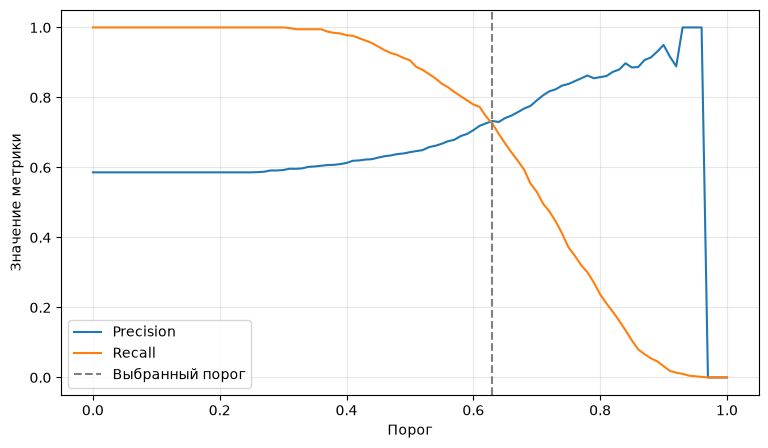

In [5]:
thresholds = np.arange(0.0, 1.01, 0.01)
rows = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    rows.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_val, y_pred, zero_division=0
        ),
    })

metrics = pd.DataFrame(rows)

valid = metrics.loc[
    (metrics["precision"] != 0) | (metrics["recall"] != 0)
].copy()

valid["difference"] = (
    valid["precision"] - valid["recall"]
).abs()

best_intersection = valid.loc[valid["difference"].idxmin()]

print("Ответ Q3:", round(best_intersection["threshold"], 2))
print("Precision:", round(best_intersection["precision"], 3))
print("Recall:", round(best_intersection["recall"], 3))

plt.figure(figsize=(9, 5))
plt.plot(metrics["threshold"], metrics["precision"], label="Precision")
plt.plot(metrics["threshold"], metrics["recall"], label="Recall")

plt.axvline(
    best_intersection["threshold"],
    color="gray",
    linestyle="--",
    label="Выбранный порог",
)

plt.xlabel("Порог")
plt.ylabel("Значение метрики")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [6]:
best_f1 = metrics.loc[metrics["f1"].idxmax()]

print("Ответ Q4:", round(best_f1["threshold"], 2))
print("F1:", round(best_f1["f1"], 6))
print("Precision:", round(best_f1["precision"], 3))
print("Recall:", round(best_f1["recall"], 3))

Ответ Q4: 0.41
F1: 0.757616
Precision: 0.619
Recall: 0.976


In [7]:
def cross_validate(C=1.0):
    kfold = KFold(
        n_splits=5,
        shuffle=True,
        random_state=1,
    )

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        fold_prob = fit_predict(fold_train, fold_val, C=C)

        auc = roc_auc_score(
            fold_val["converted"].to_numpy(),
            fold_prob,
        )

        scores.append(auc)

    return np.array(scores)


cv_scores = cross_validate(C=1.0)

for fold, score in enumerate(cv_scores, start=1):
    print(f"Fold {fold}: {score:.6f}")

print("\nСредний ROC AUC:", round(float(cv_scores.mean()), 3))
print("Ответ Q5:", round(float(np.std(cv_scores)), 3))

Fold 1: 0.730560
Fold 2: 0.729573
Fold 3: 0.736343
Fold 4: 0.741245
Fold 5: 0.720914

Средний ROC AUC: 0.732
Ответ Q5: 0.007
